## Importing the libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

This assignments has two sections:
* Linear Regression
* Kernel Regression




# Section 1:

**Linear Regression**

We will use the Boston_housing dataset for the regression problem. Run the below cell to get the following variables:
* `Training_data` = Training data matrix of shape $(n, d)$
* `labels` = label vector corresponding to the training data
* `test_data` = Test data matrix of shape $(n_1, d)$ where $n_1$ is the number of examples in test dataset.
* `test_labels` = label vector corresponding to the test data

Use this dataset for the regression problem.

In [ ]:
from keras.datasets import boston_housing
Train, test = boston_housing.load_data(seed=111)
Training_data, labels = Train[0], Train[1]
Test_data, test_labels = test[0], test[1]

## Question 1
How many examples are there in the training dataset?



In [ ]:
print(f"Number of examples in the training dataset: {Training_data.shape[0]}")

Number of examples in the training dataset: 404


## Question 2
How many examples are there in the test dataset?



In [ ]:
print(f"Number of examples in the test dataset: {Test_data.shape[0]}")

Number of examples in the test dataset: 102


## Question 3

How many features are there in the dataset?



In [ ]:
print(f"Number of features in the dataset: {Training_data.shape[1]}")

Number of features in the dataset: 13


Linear regression model for the dataset ${\mathbb{x}, y}$ is given as
$$h_w(\mathbb{x}) = w_1x^{1}+w_2x^{2}+...+w_dx^{d} =  \mathbb{x}^Tw
$$

where $x^{i}$ is the $i^{th}$ feature, $\mathbb{x}$ is the feature matrix of shape $(d, n)$ and $w = [w_1, w_2, ...w_d]^T$ is the weight vector.


Notice that above model always pass through the origin but for a given dataset, best fit model need not pass through the origin. To tackle this issue, we add an intercept $w_0$ in the model and set the corresponding featrue $x^{0}$ to $1$. That is

$$h_w(\mathbb{x}) =w_0x^{0}+ w_1x^{1}+w_2x^{2}+...+w_dx^{n} =  \mathbb{x}^Tw
$$

We call $x^{0}$ the dummy feature and set its value to 1 for each examples. Now $w$ is of shape $(d+1, 1)$ and $\mathbb{x}$ is of shape $(d+1, n)$ where the first row of $\mathbb{x}$ has entries as 1.


## Task

Add the dummy feature in the feature matrix `Training_data` and test data matrix `test_data`. We will be using this new feature matrices (after adding te dummy feature) for learning the model.

Note: As per your convenience, you can convert the shape of the training dataset to $(d, n)$.

In [ ]:
# Task: Add dummy feature (1s) to training and test data.
# We will stack a column of ones as the first column of the feature matrices.
X_train = np.column_stack((np.ones(Training_data.shape[0]), Training_data))
X_test = np.column_stack((np.ones(Test_data.shape[0]), Test_data))

# Let's align labels to be column vectors
y_train = labels.reshape(-1, 1)
y_test = test_labels.reshape(-1, 1)

print(f"New training feature matrix shape: {X_train.shape}")
print(f"New test feature matrix shape: {X_test.shape}")

New training feature matrix shape: (404, 14)
New test feature matrix shape: (102, 14)


## Question 4
If the solution of optimization problem is obtained by setting the first derivative of loss function (squared loss) to zero, find the value of $w_0+w_1+...w_d$.




In [ ]:
# Question 4: Analytical solution of weight vector using normal equation
# w = (X^T * X)^(-1) * X^T * y
w_opt = np.linalg.pinv(X_train.T @ X_train) @ X_train.T @ y_train
sum_w = np.sum(w_opt)
print(f"Sum of optimal weights (w_0 + w_1 + ... + w_d): {sum_w}")

Sum of optimal weights (w_0 + w_1 + ... + w_d): 20.524582465338845


## Question 5
Find the average of the predictions made by the above model.



In [ ]:
# Question 5: Average of predictions made by the analytical model
y_train_pred = X_train @ w_opt
avg_pred = np.mean(y_train_pred)
print(f"Average of predictions on training data: {avg_pred}")

Average of predictions on training data: 22.309158415842802


## Question 6

Find the loss for the training data points using the above model. Consider the loss to be defined as

$$ \sqrt{\dfrac{1}{n}\sum\limits_{i=1}^{n} (y_i- \hat{y}_i)^2}
$$

Where $\hat{y}_i$ is the prediction for $i^{th}$ data point.



In [ ]:
# Question 6: RMSE loss for the training data points using analytical model
train_loss = np.sqrt(np.mean((y_train - y_train_pred) ** 2))
print(f"Training RMSE loss: {train_loss}")

Training RMSE loss: 4.552387969840813


## Question 7

Find the loss for the test data points using the above model. Consider the loss to be defined as

$$ \sqrt{\dfrac{1}{n}\sum\limits_{i=1}^{n} (y_i- \hat{y}_i)^2}
$$

Where $\hat{y}_i$ is the prediction for $i^{th}$ data point.



In [ ]:
# Question 7: RMSE loss for the test data points using analytical model
y_test_pred = X_test @ w_opt
test_loss = np.sqrt(np.mean((y_test - y_test_pred) ** 2))
print(f"Test RMSE loss: {test_loss}")

Test RMSE loss: 5.32766221617725


## Question 8
Find the weights using the gradient descent. Use a constant learning rate of $\eta = 10^{-10}$. Initialize the weight vector as zero vector and update the weights for 100 iterations. Enter the sum of all the weights.



In [ ]:
# Question 8: Gradient Descent
# eta = 1e-10, 100 iterations, initialized to 0
w_gd = np.zeros((X_train.shape[1], 1))
eta = 1e-10
n = X_train.shape[0]

for _ in range(100):
    predictions = X_train @ w_gd
    gradient = (-2 / n) * X_train.T @ (y_train - predictions)
    w_gd -= eta * gradient

sum_w_gd = np.sum(w_gd)
print(f"Sum of GD weights: {sum_w_gd}")

Sum of GD weights: 0.0003928635513538252


## Question 9

Find the loss for the training data points if the model is learnt using the gradient descent as in question 8. Consider the loss to be defined as

$$ \sqrt{\dfrac{1}{n}\sum\limits_{i=1}^{n} (y_i- \hat{y}_i)^2}
$$

Where $\hat{y}_i$ is the prediction for $i^{th}$ data point.



In [ ]:
# Question 9: Train loss with GD
y_train_pred_gd = X_train @ w_gd
train_loss_gd = np.sqrt(np.mean((y_train - y_train_pred_gd) ** 2))
print(f"Training RMSE loss with GD: {train_loss_gd}")

Training RMSE loss with GD: 24.045823388028428


## Question 10

Find the loss for the test data points if the model is learnt using the gradient descent as in question 8. Consider the loss to be defined as

$$ \sqrt{\dfrac{1}{n}\sum\limits_{i=1}^{n} (y_i- \hat{y}_i)^2}
$$

Where $\hat{y}_i$ is the prediction for $i^{th}$ data point.



In [ ]:
# Question 10: Test loss with GD
y_test_pred_gd = X_test @ w_gd
test_loss_gd = np.sqrt(np.mean((y_test - y_test_pred_gd) ** 2))
print(f"Test RMSE loss with GD: {test_loss_gd}")

Test RMSE loss with GD: 24.888470189616584


## Question 11
Find the weights using the stochastic gradient descent. Use a constant learning rate of $\eta = 10^{-8}$. Initialize the weight vector as zero vector and update the weights for 1000 iterations. . Take the batch size of $⌈\text{number of samples}/5⌉ $. For sampling the batch examples in $ith$ iteration, set seed at $i$. The final weight is the last updated weight. Do not take the avearge of weights updated in all the iterations. Enter the sum of all the weights.




In [ ]:
# Question 11: SGD with batch size = ceil(n/5)
import math

w_sgd = np.zeros((X_train.shape[1], 1))
eta_sgd = 1e-8
n = X_train.shape[0]
batch_size = math.ceil(n / 5)

for i in range(1000):
    # Set seed at iteration index i
    rng_i = np.random.default_rng(seed=i)
    indices = rng_i.choice(n, size=batch_size, replace=False)
    X_batch = X_train[indices]
    y_batch = y_train[indices]

    predictions = X_batch @ w_sgd
    gradient = (-2 / batch_size) * X_batch.T @ (y_batch - predictions)
    w_sgd -= eta_sgd * gradient

sum_w_sgd = np.sum(w_sgd)
print(f"Sum of SGD weights: {sum_w_sgd}")

Sum of SGD weights: 0.06546444931448787


## Question 12

Find the loss for the training data points if the model is learnt using the stochastic gradient descent as in question 11. Consider the loss to be defined as

$$ \sqrt{\dfrac{1}{n}\sum\limits_{i=1}^{n} (y_i- \hat{y}_i)^2}
$$

Where $\hat{y}_i$ is the prediction for $i^{th}$ data point.



In [ ]:
# Question 12: Train loss with SGD
y_train_pred_sgd = X_train @ w_sgd
train_loss_sgd = np.sqrt(np.mean((y_train - y_train_pred_sgd) ** 2))
print(f"Training RMSE loss with SGD: {train_loss_sgd}")

Training RMSE loss with SGD: 10.21700925229507


## Question 13

Find the loss for the test data points if the model is learnt using the stochastic gradient descent as in question 11. Consider the loss to be defined as

$$ \sqrt{\dfrac{1}{n}\sum\limits_{i=1}^{n} (y_i- \hat{y}_i)^2}
$$

Where $\hat{y}_i$ is the prediction for $i^{th}$ data point.


In [ ]:
# Question 13: Test loss with SGD
y_test_pred_sgd = X_test @ w_sgd
test_loss_sgd = np.sqrt(np.mean((y_test - y_test_pred_sgd) ** 2))
print(f"Test RMSE loss with SGD: {test_loss_sgd}")

Test RMSE loss with SGD: 9.89938098834564


# Section 2:

**kernel Regression**

We will generate the synthetic dataset for the kernel regression problem. Run the following cell to get the following variables:

`X` = Training data matrix of shape $(n, d)$. In the given dataset $d = 1$.

`y` = label vector corresponding to the training dataset

In [ ]:
rng = np.random.default_rng(seed = 101)
X = np.arange(-2, 2, 0.01).reshape(-1, 1)
y = X**3 + rng.normal(0, 1, X.shape[0]).reshape(-1, 1)


## Question 14

Plot the scatter plot between feature and the labels. Enter your answer as 0.



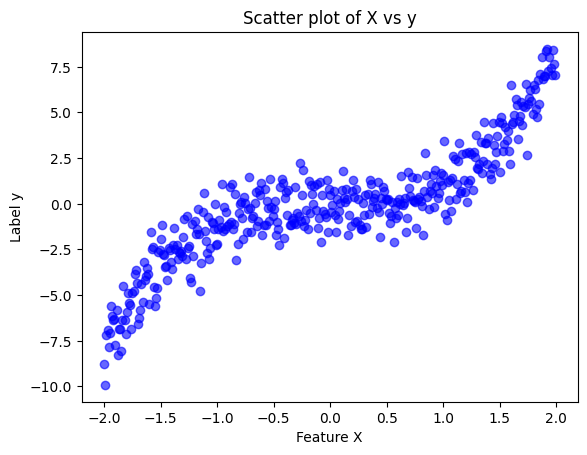

0


In [ ]:
# Question 14: Plotting the scatter plot between feature and labels
plt.scatter(X, y, alpha=0.6, color='b')
plt.xlabel('Feature X')
plt.ylabel('Label y')
plt.title('Scatter plot of X vs y')
plt.show()
print(0)

## Question 15
How many examples are there in the training dataset?



In [ ]:
# Question 15: Training data examples
print(f"Number of examples in training dataset: {X.shape[0]}")

Number of examples in training dataset: 400


## Task:

Add the dummy feature in the feature matrix `X`and reshape it to the shape $(d, n)$.

In [ ]:
# Task: Add dummy feature to X and reshape it to shape (d, n)
# First add a column of ones, then transpose it to get (d, n)
X_with_dummy = np.column_stack((np.ones(X.shape[0]), X))
X_reshaped = X_with_dummy.T
print(f"Reshaped X shape: {X_reshaped.shape}")

Reshaped X shape: (2, 400)


## Question 16

Our task is to apply the kernel regression with polynomial kernel of degree 3. We know that weight vector can be written as

$$w = \phi(\mathbb{x})\alpha$$

let us call the vector $\alpha$ as coefficient vector. Find the sum of elements in the coefficient vector.



In [ ]:
# Question 16: Kernel regression with polynomial kernel of degree 3
# K(x_i, x_j) = (1 + x_i.T @ x_j)^3
# For 1D points with dummy feature [1, x_i]^T, the inner product is 1 + x_i * x_j
K = (X_reshaped.T @ X_reshaped) ** 3
# w = Phi(X)*alpha => alpha = (K + lambda*I)^(-1) @ y
# Assuming standard kernel regression without regularization (lambda=0 or pseudo-inverse)
alpha = np.linalg.pinv(K) @ y
sum_alpha = np.sum(alpha)
print(f"Sum of elements in coefficient vector alpha: {sum_alpha}")

Sum of elements in coefficient vector alpha: -0.14248457035337334


## Question 17

Find the sum of the predictions made by the kernel regression model of degree 3.



In [ ]:
# Question 17: Sum of predictions made by kernel regression model
# y_pred = K @ alpha
y_pred_kernel = K @ alpha
sum_y_pred = np.sum(y_pred_kernel)
print(f"Sum of predictions: {sum_y_pred}")

Sum of predictions: -25.68690492009148


## Question 18

Find the loss for the training data points. Consider the loss to be defined as

$$ \sqrt{\dfrac{1}{n}\sum\limits_{i=1}^{n} (y_i- \hat{y}_i)^2}
$$

Where $\hat{y}_i$ is the prediction for $i^{th}$ data point.



In [ ]:
# Question 18: Train loss for kernel regression
train_loss_kernel = np.sqrt(np.mean((y - y_pred_kernel) ** 2))
print(f"Kernel train RMSE loss: {train_loss_kernel}")

Kernel train RMSE loss: 1.0061212525621972


### Test dataset

run the following cell to get the test data matrix `X_test` and corresponding label vector `y_test`.

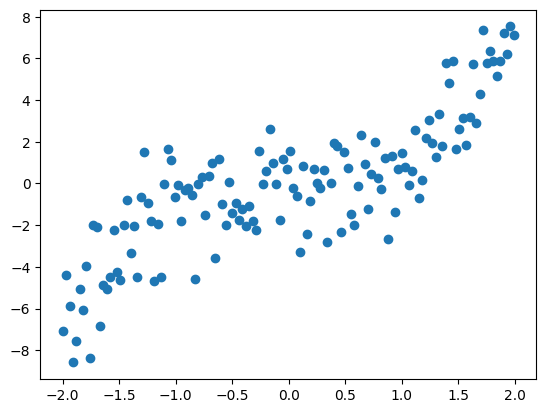

In [ ]:
rng = np.random.default_rng(seed = 102)
Xnew = np.arange(-2, 2, 0.03)
ynew = Xnew**3 + rng.normal(0, 1.5, Xnew.shape[0])
X_test = np.column_stack((np.ones(Xnew.shape[0]), Xnew.reshape(-1, 1))).T
y_test = ynew.reshape(-1, 1)
plt.scatter(Xnew,ynew)

## Question 19

Find the loss for the test data points. Consider the loss to be defined as

$$ \sqrt{\dfrac{1}{n}\sum\limits_{i=1}^{n} (y_i- \hat{y}_i)^2}
$$

Where $\hat{y}_i$ is the prediction for $i^{th}$ data point.



In [ ]:
# Question 19: Test loss for kernel regression
# X_test comes as shape (2, N_test) representing [1, x_test_i]^T
# Kernel between test and train points:
K_test = (X_test.T @ X_reshaped) ** 3
y_test_pred_kernel = K_test @ alpha
test_loss_kernel = np.sqrt(np.mean((y_test - y_test_pred_kernel) ** 2))
print(f"Kernel test RMSE loss: {test_loss_kernel}")

Kernel test RMSE loss: 1.5650996763170153
